In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists('/content/pumpkin_data'):
    !unzip -q "/content/drive/MyDrive/Original Dataset.zip" -d /content/pumpkin_data

Mounted at /content/drive


In [3]:
# Settings from Gakhar et al. (2025) - DenseNet-121 (70-20-10 Split)
# Reference [8]: "Pumpkin leaf disease detection using DenseNet-121: A deep learning approach"
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

IMG, BS, LR, EPOCHS = 224, 8, 1e-5, 50      # 224x224, batch 8, lr 1e-5, 50 epochs
STEP, GAMMA = 5, 0.1                         # lr x0.1 every 5 epochs
WD = 1e-4                                    # Adam weight decay
SPLIT = (0.70, 0.20, 0.10)                   # 70-20-10 split as reported in Gakhar et al. [8]
SPLIT_SEED, SEED = 42, 42                    # SEED: change for repeat runs
OUT = '/content/drive/MyDrive/pumpkin_runs'
os.makedirs(OUT, exist_ok=True)
RUN = f'densenet121_gakhar_702010_seed{SEED}'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)

cuda


In [4]:
def find_root(base):
    for r, dirs, _ in os.walk(base):
        if len(dirs) == 5 and all(any(f.lower().endswith(('.jpg','.jpeg','.png')) for f in os.listdir(os.path.join(r, d))) for d in dirs):
            return r
ROOT = find_root('/content/pumpkin_data')
full = datasets.ImageFolder(ROOT); classes = full.classes
paths  = [os.path.relpath(p, ROOT) for p, _ in full.samples]
labels = np.array([y for _, y in full.samples])

# 70-20-10 Stratified Split
split_file = f'{OUT}/split_702010_seed{SPLIT_SEED}.json'
if os.path.exists(split_file):
    split = json.load(open(split_file))
else:
    idx = np.arange(len(paths))
    # 70% train, 30% remainder
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SPLIT_SEED)
    # Of 30%: 2/3 for val (20% total), 1/3 for test (10% total)
    va, te = train_test_split(tmp, test_size=1/3, stratify=labels[tmp], random_state=SPLIT_SEED)
    split = dict(train=[paths[i] for i in tr], val=[paths[i] for i in va], test=[paths[i] for i in te])
    json.dump(split, open(split_file, 'w'))

tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ds = datasets.ImageFolder(ROOT, transform=tf)
p2i = {p: i for i, p in enumerate(paths)}
sub = lambda k: Subset(ds, [p2i[p] for p in split[k]])
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(sub('train'), batch_size=BS, shuffle=True, num_workers=2, generator=g)
val_loader   = DataLoader(sub('val'),   batch_size=BS, num_workers=2)
test_loader  = DataLoader(sub('test'),  batch_size=BS, num_workers=2)
print(classes, {k: len(v) for k, v in split.items()})

['Bacterial Leaf Spot', 'Downy Mildew', 'Healthy Leaf', 'Mosaic Disease', 'Powdery_Mildew'] {'train': 1400, 'val': 400, 'test': 200}


In [5]:
# Model: DenseNet-121
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
model.classifier = nn.Linear(model.classifier.in_features, len(classes))
model = model.to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"DenseNet-121 initialized with {n_params:.2f}M parameters")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP, gamma=GAMMA)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, correct / total

ckpt = f'{OUT}/best_{RUN}.pth'
best_val, hist, t0 = 0.0, [], time.time()
for ep in range(EPOCHS):
    s = time.time()
    tl, ta = run_epoch(train_loader, True); vl, va = run_epoch(val_loader, False)
    scheduler.step()
    saved = va > best_val
    if saved: best_val = va; torch.save(model.state_dict(), ckpt)
    hist.append(dict(epoch=ep+1, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
    print(f"Epoch {ep+1}/{EPOCHS} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f} | {time.time()-s:.0f}s{'  <- saved' if saved else ''}")
train_min = (time.time() - t0) / 60
pd.DataFrame(hist).to_csv(f'{OUT}/history_{RUN}.csv', index=False)
print(f'best val acc {best_val:.4f} | {train_min:.1f} min')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 197MB/s]


DenseNet-121 initialized with 6.96M parameters
Epoch 1/50 | train 1.3386/0.5171 | val 0.9824/0.7925 | 25s  <- saved
Epoch 2/50 | train 0.8670/0.7786 | val 0.6648/0.8350 | 23s  <- saved
Epoch 3/50 | train 0.6646/0.8071 | val 0.5259/0.8475 | 23s  <- saved
Epoch 4/50 | train 0.5412/0.8379 | val 0.4780/0.8475 | 23s
Epoch 5/50 | train 0.4725/0.8657 | val 0.4433/0.8550 | 23s  <- saved
Epoch 6/50 | train 0.4142/0.8771 | val 0.4325/0.8625 | 24s  <- saved
Epoch 7/50 | train 0.3968/0.8907 | val 0.4419/0.8475 | 24s
Epoch 8/50 | train 0.4054/0.8836 | val 0.4235/0.8700 | 23s  <- saved
Epoch 9/50 | train 0.3872/0.8914 | val 0.4288/0.8575 | 24s
Epoch 10/50 | train 0.4024/0.8843 | val 0.4236/0.8575 | 24s
Epoch 11/50 | train 0.3798/0.8979 | val 0.4302/0.8650 | 24s
Epoch 12/50 | train 0.3691/0.8971 | val 0.4301/0.8625 | 24s
Epoch 13/50 | train 0.3872/0.8979 | val 0.4277/0.8550 | 24s
Epoch 14/50 | train 0.3933/0.8829 | val 0.4252/0.8625 | 23s
Epoch 15/50 | train 0.4025/0.8836 | val 0.4223/0.8550 | 24s
Ep

TEST acc 0.8050 | weighted precision 0.8072 recall 0.8050 | macro F1 0.8027   (paper [8]: 94.0%)
                     precision    recall  f1-score   support

Bacterial Leaf Spot     0.7000    0.7000    0.7000        40
       Downy Mildew     0.7755    0.9500    0.8539        40
       Healthy Leaf     0.8537    0.8750    0.8642        40
     Mosaic Disease     0.9189    0.8500    0.8831        40
     Powdery_Mildew     0.7879    0.6500    0.7123        40

           accuracy                         0.8050       200
          macro avg     0.8072    0.8050    0.8027       200
       weighted avg     0.8072    0.8050    0.8027       200



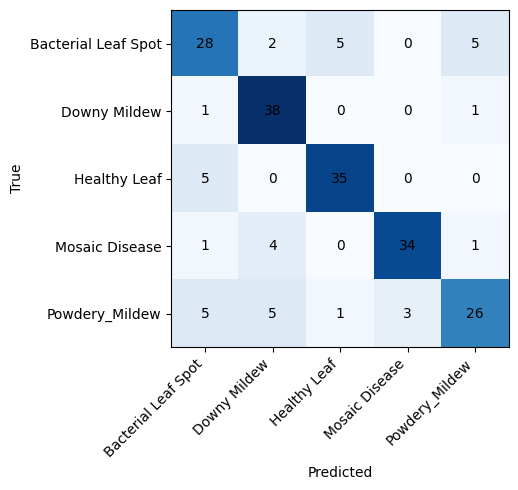

,0
Model,DenseNet-121 (Gakhar)
Reference,[8]
Seed,42
Split,70/20/10
Split file,/content/drive/MyDrive/pumpkin_runs/split_7020...
Input size,224x224
Epochs,50
Batch size,8
Learning rate,0.00001
Optimizer,"Adam wd=0.0001, StepLR 5/0.1"


In [6]:
model.load_state_dict(torch.load(ckpt)); model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist(); y_true += y.tolist()

acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
prec, rec, f1w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
_, _, f1m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
print(f'TEST acc {acc:.4f} | weighted precision {prec:.4f} recall {rec:.4f} | macro F1 {f1m:.4f}   (paper [8]: 94.0%)')
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
for i in range(5):
    for j in range(5): ax.text(j, i, cm[i, j], ha='center', va='center')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); plt.tight_layout(); plt.savefig(f'{OUT}/cm_{RUN}.png', dpi=150); plt.show()

row = {'Model': 'DenseNet-121 (Gakhar)', 'Reference': '[8]', 'Seed': SEED, 'Split': '70/20/10', 'Split file': split_file,
       'Input size': '224x224', 'Epochs': EPOCHS, 'Batch size': BS, 'Learning rate': LR,
       'Optimizer': f'Adam wd={WD}, StepLR {STEP}/{GAMMA}', 'Augmentation': 'None',
       'Best val acc': round(best_val, 4), 'Test acc': round(acc, 4), 'Macro F1': round(f1m, 4),
       'Params (M)': round(n_params, 2), 'Train time (min)': round(train_min, 1),
       'Notebook file': 'pumpkin_densenet121_gakhar.ipynb', 'Checkpoint path': ckpt}
log = f'{OUT}/run_log.csv'
pd.DataFrame([row]).to_csv(log, mode='a', header=not os.path.exists(log), index=False)
pd.DataFrame([row]).T